# Strong-Field QED Colliders with Optimized Focusing (`src/particles` Benchmark)

Numerical reproduction of Olofsson & Gonoskov, *Attaining a strong-field QED signal at laser-electron colliders with optimized focusing*, Phys. Rev. A **106**, 063512 (2022), using the `src/particles` package.

1. **Field Pack Loading & Focal Cuts**: Load `data/sample_field.npz` ($P = 100\ \mathrm{TW}, \lambda_0 = 0.8\ \mu\mathrm{m}, f = 0.25$) and inspect central $|\mathbf{E}|$ and $|\mathbf{B}|$ slices.
2. **Relativistic Trajectories & $\chi(b,t)$ Traces**: Propagate an electron ensemble with $p(b) = 2b/b_{\max}^2$ and compute $\chi(b,t)$ and high-$\chi$ residence fraction $F(b)$.
3. **Fig. 2 Phase Space (LP vs. CP)**: Compare $\ln(\partial^2 f / \partial u_\alpha \partial u_\chi)$ for linear and circular polarization.
4. **Fig. 4 Focusing Benchmark**: Plot $\chi_{\max}$ and peak field strength vs. $f$-number and opening angle $\zeta$.
5. **Fig. 5 Cross Section $\sigma$, Signal Ratio $\eta$, and $3\sigma$ Shot Statistics**: Scan $(P, \varepsilon)$ using weighted LCFA QED and compare $3\sigma$ photon vs. electron energy-loss shot counts.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.particles import (
    build_lcfa_table,
    compute_fig2_phase_space,
    compute_high_chi_time_fraction,
    compute_sigma_and_eta,
    estimate_electron_loss_shots,
    estimate_shots_for_confidence,
    f_number_to_opening_angle_deg,
    fig4_reference_curve,
    fig5_reference_contours,
    load_field_pack,
    make_analytic_bidipole_pack,
    propagate_ensemble,
    sample_electron_batch,
    simulate_qed_ensemble,
)

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

## 1. Field Pack Loading & Central Focal Cuts

Loaded field pack: pol=z-linear, P=100.0 TW, lambda0=0.80 um, f/0.25
Ec shape=(1, 3, 65, 65, 65), a_max=163.53, chi_max/GeV=1.941


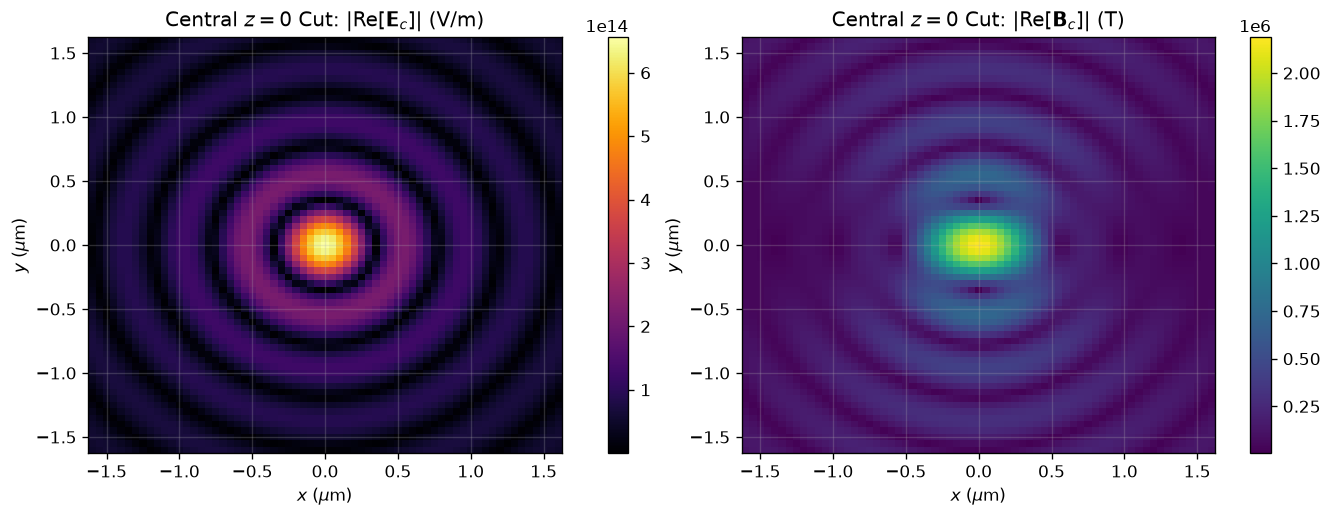

In [2]:
pack_lp = load_field_pack(REPO_ROOT / "data" / "sample_field.npz")
print(f"Loaded field pack: pol={pack_lp.pol}, P={pack_lp.power_W/1e12:.1f} TW, lambda0={pack_lp.lambda0_m*1e6:.2f} um, f/{pack_lp.f_number}")
print(f"Ec shape={pack_lp.Ec.shape}, a_max={pack_lp.checks.a_max:.2f}, chi_max/GeV={pack_lp.checks.chi_max_per_GeV:.3f}")

mid_z = pack_lp.grid.Nz // 2
e_xy = np.linalg.norm(np.real(pack_lp.Ec[0, :, mid_z, :, :]), axis=0)
b_xy = np.linalg.norm(np.real(pack_lp.Bc[0, :, mid_z, :, :]), axis=0)
x_um = pack_lp.grid.x_axis * 1e6
y_um = pack_lp.grid.y_axis * 1e6

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
im0 = axes[0].pcolormesh(x_um, y_um, e_xy, shading="auto", cmap="inferno")
axes[0].set_title(r"Central $z=0$ Cut: $|\mathrm{Re}[\mathbf{E}_c]|$ (V/m)")
axes[0].set_xlabel(r"$x$ ($\mu$m)")
axes[0].set_ylabel(r"$y$ ($\mu$m)")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].pcolormesh(x_um, y_um, b_xy, shading="auto", cmap="viridis")
axes[1].set_title(r"Central $z=0$ Cut: $|\mathrm{Re}[\mathbf{B}_c]|$ (T)")
axes[1].set_xlabel(r"$x$ ($\mu$m)")
axes[1].set_ylabel(r"$y$ ($\mu$m)")
fig.colorbar(im1, ax=axes[1])
plt.show()

## 2. Relativistic Trajectories, $\chi(b,t)$ Traces, and High-$\chi$ Fraction $F(b)$

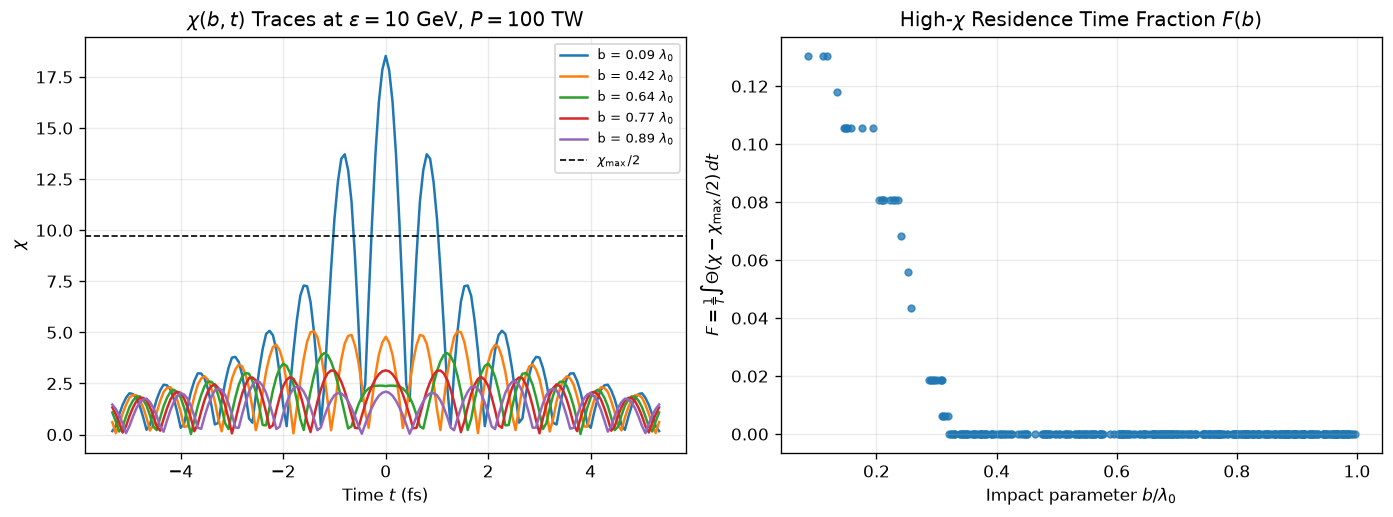

Peak simulated chi = 18.53 (reference chi_max = 19.41)


In [3]:
rng = np.random.default_rng(42)
energy_gev = 10.0
b_max_m = pack_lp.lambda0_m
batch = sample_electron_batch(
    n_particles=400,
    energy_gev=energy_gev,
    b_max_m=b_max_m,
    y0_m=pack_lp.grid.y0_m,
    rng=rng,
)
traj_lp = propagate_ensemble(pack_lp, batch, method="vay", signed_alpha=True)
chi_max_10gev = pack_lp.checks.chi_max_per_GeV * energy_gev
dt_s = float(traj_lp.t_s[1] - traj_lp.t_s[0])
high_chi_frac = compute_high_chi_time_fraction(traj_lp.chi, dt_s=dt_s, chi_max=chi_max_10gev)

order = np.argsort(batch.b_impact_m)
sample_indices = order[::80]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
for idx in sample_indices:
    axes[0].plot(
        traj_lp.t_s * 1e15,
        traj_lp.chi[idx],
        label=f"b = {batch.b_impact_m[idx]/pack_lp.lambda0_m:.2f} $\\lambda_0$",
    )
axes[0].axhline(0.5 * chi_max_10gev, color="k", linestyle="--", linewidth=1.0, label=r"$\chi_{\max}/2$")
axes[0].set_title(r"$\chi(b,t)$ Traces at $\varepsilon = 10$ GeV, $P = 100$ TW")
axes[0].set_xlabel("Time $t$ (fs)")
axes[0].set_ylabel(r"$\chi$")
axes[0].legend(fontsize=8)

axes[1].scatter(batch.b_impact_m / pack_lp.lambda0_m, high_chi_frac, s=16, alpha=0.75)
axes[1].set_title(r"High-$\chi$ Residence Time Fraction $F(b)$")
axes[1].set_xlabel(r"Impact parameter $b / \lambda_0$")
axes[1].set_ylabel(r"$F = \frac{1}{T}\int \Theta(\chi - \chi_{\max}/2)\,dt$")
plt.show()

print(f"Peak simulated chi = {np.max(traj_lp.chi):.2f} (reference chi_max = {chi_max_10gev:.2f})")

## 3. Fig. 2 Reproduction: LP vs. CP Phase Space $\ln(\partial^2 f / \partial u_\alpha \partial u_\chi)$

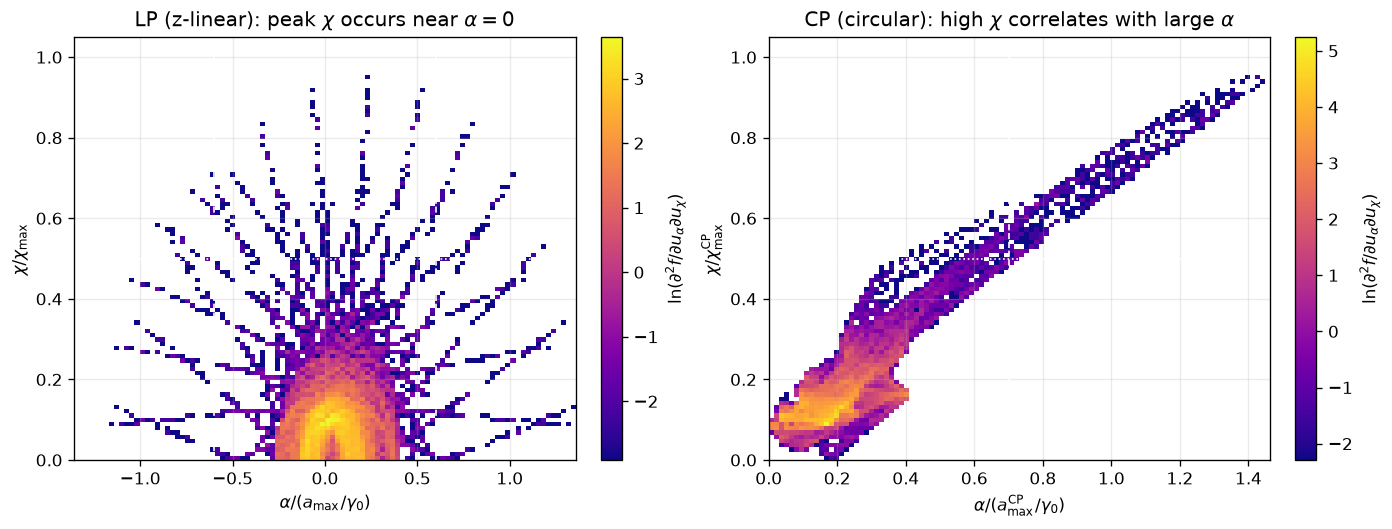

In [4]:
pack_cp = make_analytic_bidipole_pack(
    power_w=pack_lp.power_W,
    lambda0_m=pack_lp.lambda0_m,
    f_number=pack_lp.f_number,
    pol="circular",
)
traj_cp = propagate_ensemble(pack_cp, batch, method="vay", signed_alpha=False)

ps_lp = compute_fig2_phase_space(
    traj_lp.alpha,
    traj_lp.chi,
    a_max=pack_lp.checks.a_max,
    gamma0=batch.gamma0,
    chi_max=pack_lp.checks.chi_max_per_GeV * energy_gev,
    signed_alpha=True,
    n_bins_alpha=100,
    n_bins_chi=100,
)
ps_cp = compute_fig2_phase_space(
    traj_cp.alpha,
    traj_cp.chi,
    a_max=pack_cp.checks.a_max,
    gamma0=batch.gamma0,
    chi_max=pack_cp.checks.chi_max_per_GeV * energy_gev,
    signed_alpha=False,
    n_bins_alpha=100,
    n_bins_chi=100,
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), constrained_layout=True)
im_lp = axes[0].pcolormesh(
    ps_lp["u_alpha_edges"], ps_lp["u_chi_edges"], ps_lp["log_density"], cmap="plasma"
)
axes[0].axvline(-0.6, color="w", linestyle="--", linewidth=1.0)
axes[0].axvline(0.6, color="w", linestyle="--", linewidth=1.0)
axes[0].axhline(0.5, color="w", linestyle=":", linewidth=1.0)
axes[0].set_title("LP (z-linear): peak $\\chi$ occurs near $\\alpha = 0$")
axes[0].set_xlabel(r"$\alpha / (a_{\max} / \gamma_0)$")
axes[0].set_ylabel(r"$\chi / \chi_{\max}$")
fig.colorbar(im_lp, ax=axes[0], label=r"$\ln(\partial^2 f / \partial u_\alpha \partial u_\chi)$")

im_cp = axes[1].pcolormesh(
    ps_cp["u_alpha_edges"], ps_cp["u_chi_edges"], ps_cp["log_density"], cmap="plasma"
)
axes[1].axvline(0.7, color="w", linestyle="--", linewidth=1.0)
axes[1].axhline(0.5, color="w", linestyle=":", linewidth=1.0)
axes[1].set_title("CP (circular): high $\\chi$ correlates with large $\\alpha$")
axes[1].set_xlabel(r"$\alpha / (a_{\max}^{\mathrm{CP}} / \gamma_0)$")
axes[1].set_ylabel(r"$\chi / \chi_{\max}^{\mathrm{CP}}$")
fig.colorbar(im_cp, ax=axes[1], label=r"$\ln(\partial^2 f / \partial u_\alpha \partial u_\chi)$")
plt.show()

## 4. Fig. 4 Benchmark: $\chi_{\max}$ and Peak Field vs. $f$-number & Opening Angle $\zeta$

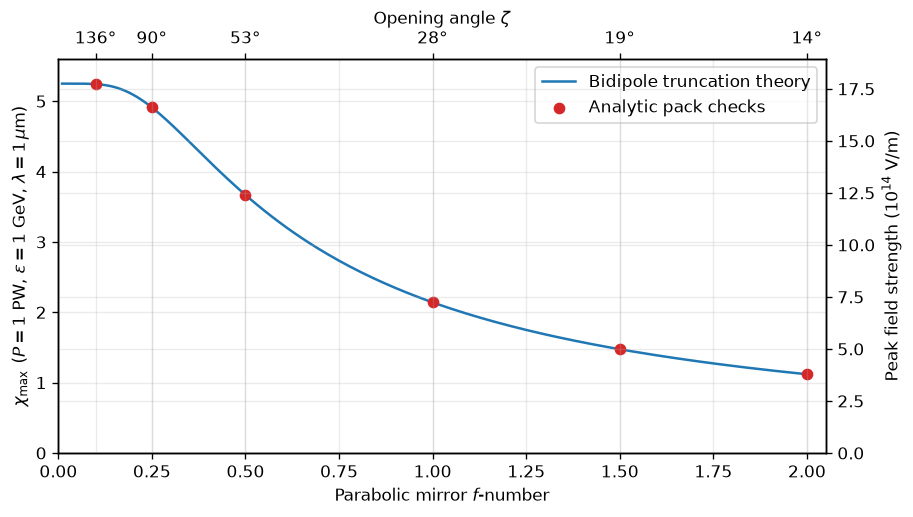

In [5]:
f4 = fig4_reference_curve(power_w=1e15, energy_gev=1.0, lambda_m=1e-6)
spot_f = np.array([0.1, 0.25, 0.5, 1.0, 1.5, 2.0])
spot_chi = [
    make_analytic_bidipole_pack(power_w=1e15, lambda0_m=1e-6, f_number=float(fv), n_grid=17).checks.chi_max_per_GeV
    for fv in spot_f
]

fig, ax1 = plt.subplots(figsize=(7.5, 4.2), constrained_layout=True)
ax1.plot(f4["f_numbers"], f4["chi_max"], label="Bidipole truncation theory")
ax1.scatter(spot_f, spot_chi, color="tab:red", zorder=4, label="Analytic pack checks")
ax1.set_xlabel("Parabolic mirror $f$-number")
ax1.set_ylabel(r"$\chi_{\max}$ ($P=1$ PW, $\varepsilon=1$ GeV, $\lambda=1\,\mu$m)")
ax1.set_xlim(0.0, 2.05)
ax1.set_ylim(0.0, 5.6)

ax2 = ax1.twinx()
ax2.plot(f4["f_numbers"], f4["field_strength_1e14_vm"], alpha=0.0)
ax2.set_ylabel(r"Peak field strength ($10^{14}$ V/m)")
scale_vm = f4["field_strength_1e14_vm"][0] / f4["chi_max"][0]
ax2.set_ylim(0.0, 5.6 * scale_vm)

ax_top = ax1.twiny()
tick_f = np.array([0.1, 0.25, 0.5, 1.0, 1.5, 2.0])
ax_top.set_xlim(ax1.get_xlim())
ax_top.set_xticks(tick_f)
ax_top.set_xticklabels([f"{f_number_to_opening_angle_deg(fv):.0f}°" for fv in tick_f])
ax_top.set_xlabel(r"Opening angle $\zeta$")
ax1.legend(loc="upper right")
plt.show()

## 5. Fig. 5 QED Cross Section $\sigma$, Signal Ratio $\eta$, and $3\sigma$ Shot Statistics

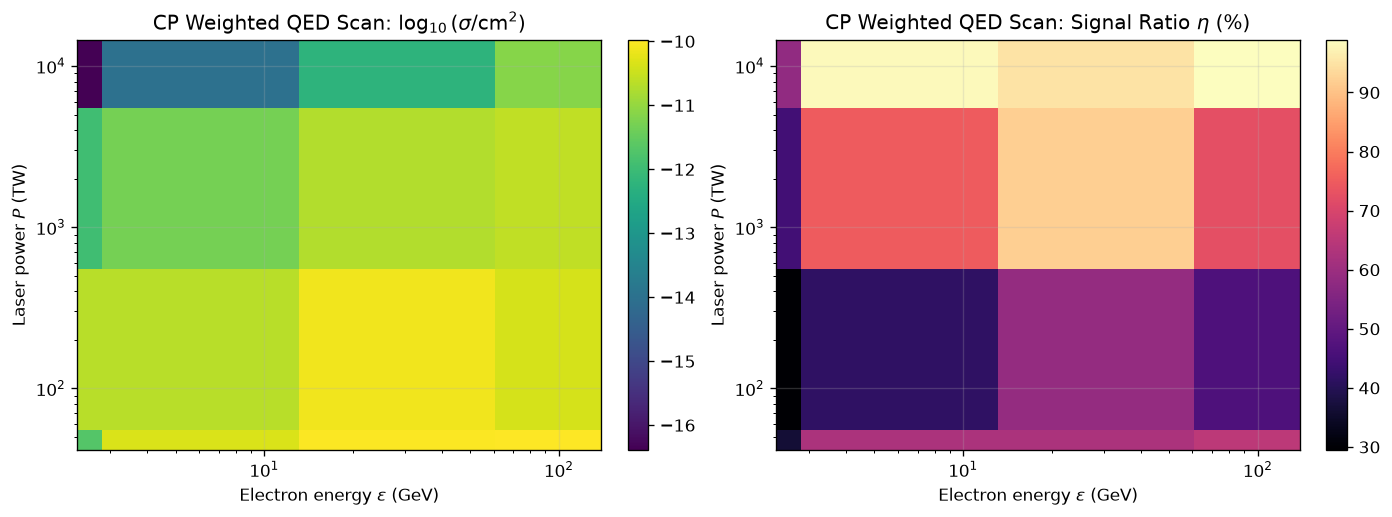

3-sigma photon diagnostic shots (sigma=1e-11 cm^2, eta=0.1): 225.0 (~200 in Sec. V)
3-sigma electron energy-loss shots: 8.13e+06 (paper rounded mfp=0.15 lambda: 5.50e+07 ~ 1e8)


In [6]:
table = build_lcfa_table()
energies = np.geomspace(1.0, 100.0, 4)
powers = np.geomspace(1e13, 1e16, 4)
sigma_grid = np.zeros((powers.size, energies.size))
eta_grid = np.zeros((powers.size, energies.size))

scan_rng = np.random.default_rng(2025)
for ip, pw in enumerate(powers):
    pack_scan = make_analytic_bidipole_pack(
        power_w=float(pw),
        lambda0_m=0.8e-6,
        f_number=0.25,
        pol="circular",
        n_grid=41,
    )
    for ie, en in enumerate(energies):
        b_scan = sample_electron_batch(
            n_particles=120,
            energy_gev=float(en),
            b_max_m=pack_scan.lambda0_m,
            y0_m=pack_scan.grid.y0_m,
            rng=scan_rng,
        )
        res = simulate_qed_ensemble(pack_scan, b_scan, mode="weighted", table=table)
        metrics = compute_sigma_and_eta(
            res.photons,
            pol=pack_scan.pol,
            a_max=pack_scan.checks.a_max,
            chi_max=pack_scan.checks.chi_max_per_GeV * float(en),
            b_max_m=pack_scan.lambda0_m,
            n_electrons=len(b_scan.b_impact_m),
        )
        sigma_grid[ip, ie] = max(metrics["sigma_cm2"], 1e-18)
        eta_grid[ip, ie] = metrics["eta"]

f5 = fig5_reference_contours(energies, powers, lambda_m=0.8e-6, kappa=pack_lp.checks.chi_max_per_GeV * (0.8 / np.sqrt(1e14 / 1e15)))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
im_s = axes[0].pcolormesh(energies, powers / 1e12, np.log10(sigma_grid), shading="auto", cmap="viridis")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title(r"CP Weighted QED Scan: $\log_{10}(\sigma / \mathrm{cm}^2)$")
axes[0].set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
axes[0].set_ylabel("Laser power $P$ (TW)")
fig.colorbar(im_s, ax=axes[0])

im_e = axes[1].pcolormesh(energies, powers / 1e12, 100.0 * eta_grid, shading="auto", cmap="magma")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title(r"CP Weighted QED Scan: Signal Ratio $\eta$ (%)")
axes[1].set_xlabel(r"Electron energy $\varepsilon$ (GeV)")
axes[1].set_ylabel("Laser power $P$ (TW)")
fig.colorbar(im_e, ax=axes[1])
plt.show()

# Benchmark 3-sigma shot comparison at 10 GeV, 100 TW
shot_est = estimate_shots_for_confidence(
    sigma_cm2=1e-11,
    eta=0.1,
    n_e_cm3=1e19,
    tau_l_s=pack_lp.pulse.tau_fwhm_s,
)
eloss = estimate_electron_loss_shots()
print(f"3-sigma photon diagnostic shots (sigma=1e-11 cm^2, eta=0.1): {shot_est.n_shots_required:.1f} (~200 in Sec. V)")
print(
    f"3-sigma electron energy-loss shots: {eloss['shots_required']:.2e} "
    f"(paper rounded mfp=0.15 lambda: {eloss['shots_required_paper_rounded']:.2e} ~ 1e8)"
)